# Model B, Taken Apart: a Hands-On Primer
**Series B: Deep Learning for Molecules, Post 6f** &nbsp;|&nbsp; companion *primer* notebook

Model B (Shee, Li, Zhang, ..., Newhouse and Batista, *Nature Communications* **15**, 7818, 2024) is Model A with one change: the **user chooses the reaction centers**, the atoms of the product that must change, and the model writes **only the template** for exactly those atoms. The chosen atoms enter the network as an extra embedding added to the product tokens. This is how the authors steered the model to the shortest route for their target (Post 6f), and it is why Model B's accuracy is a *conditional* accuracy: it is given the answer's sites.

> **Two parts.** **Part I** needs only NumPy, pandas and matplotlib (about a minute); with the code folder `single_step_retro-main` it also runs the authors' **real Model B checkpoint** in NumPy (no PyTorch, no RDKit) and reproduces what the authors saved. **Part II** runs the authors' PyTorch and RDKit code (applying templates, drawing reactions) and needs both.
>
> Without RDKit, Part I works with template *strings*; it cannot apply a template to a molecule. Accuracies are the authors'.

| Section | What you do |
|---|---|
| 1 | choose reaction centers; build the star positions the network receives |
| 2 | the center embedding: no new parameters, one added vector |
| 3 | **(real weights)** what Model B writes for each choice of centers; a map over all bonds |
| 4 | **(real weights)** do Models A and B agree? |
| 5 | the price of knowing the centers; the route of the paper |
| **Part II** | run the authors' code and draw the reactions |

## 0. Setup

In [1]:
import itertools, math, re, io, os, sys, pickle, zipfile, collections, time, textwrap, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")

def _as_code_dir(p):
    """p may be the code folder or its 'code' subfolder: return the folder that contains model_library, or None."""
    p = Path(p)
    for q in (p, p / "code"):
        if q.is_dir() and (q / "model_library").is_dir(): return q.resolve()
    return None

def _search(root, max_depth=3, deadline=None, want="model_library"):
    """Walk `root` (at most `max_depth` levels down, skipping hidden folders, stopping at `deadline`) for a folder that contains `want` (case-insensitive)."""
    root = Path(root)
    if not root.is_dir(): return None
    base = len(root.parts)
    for dirpath, dirnames, _ in os.walk(root):
        if deadline and time.time() > deadline: return None
        hit = next((d for d in dirnames if d.lower() == want), None)
        if hit: return Path(dirpath).resolve()
        if len(Path(dirpath).parts) - base >= max_depth: dirnames[:] = []
        dirnames[:] = [d for d in dirnames if not d.startswith(".")]
    return None

def _find_zip(root, max_depth, deadline):
    root = Path(root); base = len(root.parts)
    for dirpath, dirnames, files in os.walk(root):
        if time.time() > deadline: return None
        for f in files:
            if f.lower().startswith("single_step_retro") and f.lower().endswith(".zip"): return Path(dirpath) / f
        if len(Path(dirpath).parts) - base >= max_depth: dirnames[:] = []
        dirnames[:] = [d for d in dirnames if not d.startswith(".")]
    return None

def _find_generic(mount_drive=True, max_depth=3, deep_seconds=90):
    """Find the authors' code folder 'single_step_retro-main': the folder that contains model_library.
    Order: environment variable CAPSULE_DIR; the working folder and /content; Google Drive (My Drive, 'Colab Notebooks');
    then a DEEP, time-limited search of Drive for the folder (or for single_step_retro*.zip, which is unzipped into /content/code_unzipped).
    In Colab it offers to mount Google Drive if the code folder is not found elsewhere."""
    hit = _as_code_dir(os.environ["CAPSULE_DIR"]) if os.environ.get("CAPSULE_DIR") else None
    if hit: return hit
    def roots():
        r = [Path.cwd()] + ([Path.cwd().parent] if len(Path.cwd().parent.parts) > 2 else []) + [Path("/content")]      # never walk "/" or a top-level system folder
        for drive in ("/content/drive/MyDrive", "/content/drive/My Drive", "/content/gdrive/MyDrive"):
            r += [Path(drive), Path(drive) / "Colab Notebooks"]
        return [x for x in dict.fromkeys(r) if x.is_dir()]
    def look():
        for r in roots():                                                         # the usual places first (cheap)
            for q in (r / "single_step_retro-main", r / "code", r):
                hit = _as_code_dir(q)
                if hit: return hit
        for r in roots():                                                         # a shallow search
            hit = _search(r, max_depth)
            if hit: return hit
        drives = [r for r in roots() if "drive" in str(r).lower() or "gdrive" in str(r).lower()]
        if drives:                                                                # a deep, time-limited search of Drive
            print(f"searching Google Drive more deeply (at most {deep_seconds} s) ...")
            deadline = time.time() + deep_seconds
            for r in drives[:1] + [d for d in drives[1:] if not str(d).startswith(str(drives[0]))]:
                hit = _search(r, 8, deadline)
                if hit: return hit
            for r in drives[:1]:
                z = _find_zip(r, 8, deadline)
                if z:
                    target = Path("/content/code_unzipped"); print("found", z, "-> unzipping into", target)
                    subprocess.run(["unzip", "-q", "-o", str(z), "-d", str(target)], check=False); hit = _search(target, 4)
                    if hit: return hit
        for r in roots():                                                         # a zip next to the notebook
            for z in sorted(r.glob("single_step_retro*.zip")):
                target = r / z.stem
                if not target.exists(): print("unzipping", z, "->", target); subprocess.run(["unzip", "-q", "-o", str(z), "-d", str(r)], check=False)
                hit = _search(r / z.stem, max_depth + 1) or _search(r, max_depth)
                if hit: return hit
        return None
    hit = look()
    if hit is None and mount_drive and not Path("/content/drive").exists():
        try:
            from google.colab import drive                                        # only exists in Colab; asks for your permission
            drive.mount("/content/drive"); hit = look()
        except Exception as e:
            print("(Google Drive was not mounted:", type(e).__name__, ")")
    if hit is None:                                                               # help the user see what Colab can see
        for r in roots():
            try: print(f"  {r}:", sorted(p.name for p in r.iterdir())[:20])
            except Exception as e: print(f"  {r}: cannot list ({type(e).__name__})")
    return hit


def find_capsule(**kw):
    # Stage 1: look for a folder named exactly 'single_step_retro-main' (the folder this notebook is written for), up to 8 levels deep in the working folder, /content and Google Drive. Stage 2: the generic search for any folder that contains model_library.
    env = os.environ.get("CAPSULE_DIR")
    if env and _as_code_dir(env): return _as_code_dir(env)
    if not Path("/content/drive").exists():
        try:
            from google.colab import drive; drive.mount("/content/drive")                       # only in Colab; asks for your permission
        except Exception: pass
    roots = [Path.cwd()] + ([Path.cwd().parent] if len(Path.cwd().parent.parts) > 2 else []) + [Path("/content")] + [Path(p) for p in ("/content/drive/MyDrive", "/content/drive/My Drive")]      # never walk "/" or a top-level system folder
    deadline = time.time() + 60
    for r in dict.fromkeys(x for x in roots if x.is_dir()):
        base = len(r.parts)
        for dirpath, dirnames, _ in os.walk(r):
            if time.time() > deadline: break
            if "single_step_retro-main" in dirnames and _as_code_dir(Path(dirpath) / "single_step_retro-main"): return _as_code_dir(Path(dirpath) / "single_step_retro-main")
            if len(Path(dirpath).parts) - base >= 8: dirnames[:] = []
            dirnames[:] = [d for d in dirnames if not d.startswith(".")]
    return _find_generic(**kw)

CAPSULE = find_capsule()
print("code folder found at:", CAPSULE if CAPSULE else "NOT FOUND: put the folder 'single_step_retro-main' (or its zip) next to this notebook, in /content, or in My Drive / Colab Notebooks, or set CAPSULE_DIR; to try your own prompt without the code, use https://models.batistalab.com/")

Mounted at /content/drive
code folder found at: /content/drive/MyDrive/Colab Notebooks/ML/temp/Blogs/single_step_retro-main


In [2]:
# ---- reading the authors' pickles WITHOUT executing anything: list what a pickle would import, then read it with a whitelist-only reader
import pickletools
def pickle_globals(data):
    strs, found = [], set()
    for op, arg, pos in pickletools.genops(data):
        if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE"): strs.append(arg)
        if op.name == "GLOBAL": found.add(arg.replace(" ", "."))
        if op.name == "STACK_GLOBAL" and len(strs) >= 2: found.add(strs[-2] + "." + strs[-1])
    return sorted(found)

class _NoGlobals(pickle.Unpickler):
    def find_class(self, module, name): raise pickle.UnpicklingError(f"refused global {module}.{name}")
def load_plain_pickle(path):                                                           # for the small dictionary pickles (they import nothing)
    data = Path(path).read_bytes(); assert pickle_globals(data) == [], pickle_globals(data)
    return _NoGlobals(io.BytesIO(data)).load()

class _Storage:
    def __init__(self, key, numel): self.key, self.numel = key, numel
class _FloatStorage: pass
def _rebuild_tensor_v2(storage, offset, size, stride, requires_grad=False, backward_hooks=None, metadata=None): return ("tensor", storage, offset, tuple(size), tuple(stride))
class _CkptUnpickler(pickle.Unpickler):
    ALLOWED = {("collections", "OrderedDict"): collections.OrderedDict, ("torch", "FloatStorage"): _FloatStorage, ("torch._utils", "_rebuild_tensor_v2"): _rebuild_tensor_v2}
    def find_class(self, module, name):
        if (module, name) in self.ALLOWED: return self.ALLOWED[(module, name)]
        raise pickle.UnpicklingError(f"refused global {module}.{name}")
    def persistent_load(self, pid): return _Storage(str(pid[2]), int(pid[4]))

def load_checkpoint_numpy(path):
    """Read a PyTorch checkpoint (a zip with a pickle and raw tensor files) as NumPy arrays, importing only three standard tensor-storage names."""
    z = zipfile.ZipFile(path); pk = [n for n in z.namelist() if n.endswith("data.pkl")][0]; root = pk[:-len("data.pkl")]
    allowed = {"collections.OrderedDict", "torch.FloatStorage", "torch._utils._rebuild_tensor_v2"}
    unexpected = set(pickle_globals(z.read(pk))) - allowed
    assert not unexpected, f"the checkpoint imports something unexpected: {unexpected}"
    obj = _CkptUnpickler(io.BytesIO(z.read(pk))).load()
    def mat(o):
        if isinstance(o, tuple) and len(o) == 5 and o[0] == "tensor":
            _, st, off, size, stride = o; raw = np.frombuffer(z.read(root + "data/" + st.key), dtype="<f4")
            return np.lib.stride_tricks.as_strided(raw[off:], shape=size, strides=[s * 4 for s in stride]).copy() if len(size) else raw[off:off + 1].copy()
        if isinstance(o, dict): return type(o)((k, mat(v)) for k, v in o.items())
        if isinstance(o, (list, tuple)): return type(o)(mat(v) for v in o)
        return o
    return mat(obj)
print("safe readers defined")

safe readers defined


In [3]:
# ---- the tokenizer: characters, with two-letter atoms merged and '>>' merged; <SOS> first, '?' last (our re-implementation of the authors' 'character_consider_atoms')
TWO_LETTER_ATOMS = ["Ag","Al","As","Bi","Br","Ca","Cl","Cr","Cu","Ga","Ge","Hg","Li","Mg","Mn","Na","Pb","Pt","Ru","Sb","Se","Si","Sn","Ta","Te","Ti","Tl","Xe","Zn","Zr","se","si","te","Mo","Re"]
def tokenize(s):
    toks, has_added, skip = ["<SOS>"], False, False
    for i, c in enumerate(s):
        if skip: skip = False; continue
        if i < len(s) - 1 and c + s[i + 1] in TWO_LETTER_ATOMS: skip = True; toks.append(c + s[i + 1])
        elif c != ">": toks.append(c)
        elif not has_added: toks.append(">>"); has_added = True
    return toks + ["?"]

# ---- atoms in a SMILES string, in RDKit's numbering (the order of appearance), without RDKit
def smiles_atom_spans(smiles):
    spans, i, n = [], 0, len(smiles)
    while i < n:
        c = smiles[i]
        if c == "[":
            j = smiles.index("]", i); k = i + 1
            while k < j and smiles[k].isdigit(): k += 1                                   # isotope
            m = re.match(r"(Cl|Br|Si|Mg|Mn|Li|Cr|Cu|Zn|Al|Na|Ti|Ge|Zr|Bi|Sb|Te|As|Mo|Ga|Hg|Ta|Pb|Ru|Pt|Xe|Tl|Re|Ag|Ca|Sn|Se|se|si|te|[A-Za-z*])", smiles[k:j])
            spans.append((k, k + len(m.group(1)))); i = j + 1
        elif smiles[i:i + 2] in ("Cl", "Br"): spans.append((i, i + 2)); i += 2
        elif c in "BCNOPSFIbcnops*": spans.append((i, i + 1)); i += 1
        elif c == "%": i += 3
        else: i += 1                                                                   # bonds, branches, ring digits, '.', stereo marks
    return spans

def to_center_labeled(smiles, centers):
    """The center-labeled product: the element symbol of every atom whose index is in `centers` is replaced by '*'."""
    spans = smiles_atom_spans(smiles); out, last = [], 0
    for idx, (a, b) in enumerate(spans):
        out.append(smiles[last:a]); out.append("*" if idx in centers else smiles[a:b]); last = b
    out.append(smiles[last:]); return "".join(out)

def centers_of(center_labeled):
    return [i for i, (a, b) in enumerate(smiles_atom_spans(center_labeled)) if center_labeled[a:b] == "*"]

def star_positions(center_labeled):
    """Positions of the '*' tokens in the token sequence (position 0 is <SOS>): what Model B adds a '*' embedding at."""
    return [i for i, t in enumerate(tokenize(center_labeled)) if t == "*"]

def template_anatomy(template):
    """Split a retro template 'product side >> reactant side' into its parts."""
    left, right = template.split(">>"); maps = lambda s: re.findall(r":(\d+)\]", s)
    return dict(product_side=left, reactant_side=right, mapped_atoms=len(set(maps(left))), unmapped_new_atoms=len(re.findall(r"\[[^\]:]+\]|Br|Cl|[BCNOPSFI]", re.sub(r"\[[^\]]*:\d+\]", "", right))),
                reactant_fragments=len(right.split(".")), product_fragments=len(left.split(".")), intramolecular=len(left.split(".")) > 1)

# ---- tests against center-labeled products that the authors saved in their notebooks
assert to_center_labeled("C#CC1(C)CCCCC1=O", [0, 1]) == "*#*C1(C)CCCCC1=O"
_p = "CC(=O)OCC(=O)[C@@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C)C3=CC[C@]12C"
assert to_center_labeled(_p, [5, 6, 4, 3, 1, 2]) == "C*(=*)***(=*)[C@@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C)C3=CC[C@]12C"
_q, _clp = "CC(=O)c1ccc(Cn2ncc(NC(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1", "C*(=*)c1ccc(Cn2ncc(**(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1"
assert to_center_labeled(_q, centers_of(_clp)) == _clp and centers_of(_clp) == [1, 2, 12, 13]
assert star_positions("*#*C1(C)CCCCC1=O") == [1, 3]
print("the string-level atom tools reproduce the center-labeled products saved in the authors' notebooks")

the string-level atom tools reproduce the center-labeled products saved in the authors' notebooks


In [4]:
# ---- parameter counts of the Transformer (Model A / B shapes), from the architecture alone
def transformer_params(in_vocab, out_vocab, d=256, ff=512, layers=6, enc_len=310, dec_len=350):
    ln, mha = 2 * d, 4 * (d * d + d); fnn = d * ff + ff + ff * d + d
    enc = in_vocab * d + enc_len * d + layers * (2 * ln + mha + fnn)
    dec = out_vocab * d + dec_len * d + layers * (3 * ln + 2 * mha + fnn) + d * out_vocab + out_vocab
    return enc, dec

In [5]:
# ---- the authors' Model A / Model B network in NumPy: post-norm Transformer, learned position embeddings, ReLU feed-forward, 6+6 layers
def softmax(x, ax=-1):
    e = np.exp(x - x.max(ax, keepdims=True)); return e / e.sum(ax, keepdims=True)
def layer_norm(x, w, b, eps=1e-5):
    m = x.mean(-1, keepdims=True); v = x.var(-1, keepdims=True); return (x - m) / np.sqrt(v + eps) * w + b
def linear(x, W, b): return x @ W.T + b                                               # PyTorch stores nn.Linear weights as (out, in)

class TemplateTransformerNP:
    def __init__(self, sd, n_heads=8, n_layers=6):
        self.sd, self.h, self.L = sd, n_heads, n_layers; self.d = sd["decoder.tok_embedding.weight"].shape[1]
    def attention(self, p, q_in, kv_in, keep):                                         # keep: True where attention is allowed
        sd, d, h = self.sd, self.d, self.h; dh = d // h; B, Lq, _ = q_in.shape; Lk = kv_in.shape[1]
        Q = linear(q_in, sd[p + ".fc_q.weight"], sd[p + ".fc_q.bias"]).reshape(B, Lq, h, dh).transpose(0, 2, 1, 3)
        K = linear(kv_in, sd[p + ".fc_k.weight"], sd[p + ".fc_k.bias"]).reshape(B, Lk, h, dh).transpose(0, 2, 1, 3)
        V = linear(kv_in, sd[p + ".fc_v.weight"], sd[p + ".fc_v.bias"]).reshape(B, Lk, h, dh).transpose(0, 2, 1, 3)
        e = np.where(keep, Q @ K.transpose(0, 1, 3, 2) / math.sqrt(dh), -1e10); a = softmax(e)
        return linear((a @ V).transpose(0, 2, 1, 3).reshape(B, Lq, d), sd[p + ".fc_o.weight"], sd[p + ".fc_o.bias"]), a
    def feed_forward(self, p, x):
        sd = self.sd; return linear(np.maximum(linear(x, sd[p + ".fc_1.weight"], sd[p + ".fc_1.bias"]), 0), sd[p + ".fc_2.weight"], sd[p + ".fc_2.bias"])
    def encode(self, product, pad_idx, star_positions=None, star_token=None):
        """product: (B, Ls) token ids. star_positions (Model B): list of positions per example; a '*' embedding is ADDED there."""
        sd, d = self.sd, self.d; pre = "conditioner.encoder."; B, Ls = product.shape; keep = (product != pad_idx)[:, None, None, :]
        x = sd[pre + "tok_embedding.weight"][product]
        if star_positions is not None:
            onehot = np.zeros((B, Ls), dtype=np.int64)
            for b in range(B):
                for pos in star_positions[b]:
                    if pos > 0: onehot[b, pos] = star_token                            # position 0 is reserved, as in the authors' code
            x = x + sd[pre + "tok_embedding.weight"][onehot] * (onehot != 0)[..., None]
        x = x * math.sqrt(d) + sd[pre + "pos_embedding.weight"][np.arange(Ls)][None]
        for l in range(self.L):
            p = f"{pre}layers.{l}"; a, _ = self.attention(p + ".self_attention", x, x, keep)
            x = layer_norm(x + a, sd[p + ".self_attn_layer_norm.weight"], sd[p + ".self_attn_layer_norm.bias"])
            x = layer_norm(x + self.feed_forward(p + ".positionwise_feedforward", x), sd[p + ".ff_layer_norm.weight"], sd[p + ".ff_layer_norm.bias"])
        return x, keep
    def decode(self, trg, memory, memory_keep, pad_idx):
        sd, d = self.sd, self.d; B, t = trg.shape
        x = sd["decoder.tok_embedding.weight"][trg] * math.sqrt(d) + sd["decoder.pos_embedding.weight"][np.arange(t)][None]
        keep = (trg != pad_idx)[:, None, None, :] & np.tril(np.ones((t, t), dtype=bool))[None, None]; att = None
        for l in range(self.L):
            p = f"decoder.layers.{l}"; a, _ = self.attention(p + ".self_attention", x, x, keep)
            x = layer_norm(x + a, sd[p + ".self_attn_layer_norm.weight"], sd[p + ".self_attn_layer_norm.bias"])
            a, att = self.attention(p + ".encoder_attention", x, memory, memory_keep)
            x = layer_norm(x + a, sd[p + ".enc_attn_layer_norm.weight"], sd[p + ".enc_attn_layer_norm.bias"])
            x = layer_norm(x + self.feed_forward(p + ".positionwise_feedforward", x), sd[p + ".ff_layer_norm.weight"], sd[p + ".ff_layer_norm.bias"])
        return linear(x, sd["decoder.fc_out.weight"], sd["decoder.fc_out.bias"]), att        # logits and the LAST layer's cross-attention (B, heads, t, Ls)

def beam_search(model, smiledict, invdict, product_tokens, beam_size=10, star_positions=None, max_len=349, product_len=310):
    """The authors' beam search, re-implemented: candidates are ranked by log-probability / sqrt(number of non-pad tokens); finished beams (token '?') are carried along."""
    pad, end = len(smiledict), smiledict["?"]
    prod = np.array([[smiledict[t] for t in product_tokens] + [pad] * (product_len - len(product_tokens))])
    mem, keep = model.encode(prod, pad, None if star_positions is None else [star_positions], smiledict.get("*"))
    logits, _ = model.decode(np.zeros((1, 1), dtype=np.int64), mem, keep, pad)
    lp = np.log(softmax(logits[0, -1])); top = np.minimum(np.argsort(lp)[::-1][:beam_size], pad)
    seqs = [[0, int(t)] for t in top]; probs = np.array([lp[t] for t in top])
    for step in range(max_len - 2):
        if all(end in s for s in seqs): break                                           # (the authors' code keeps looping with padding; the result is the same)
        L = max(len(s) for s in seqs); trg = np.array([s + [pad] * (L - len(s)) for s in seqs])
        logits, _ = model.decode(trg, np.repeat(mem, len(seqs), 0), np.repeat(keep, len(seqs), 0), pad); cs, cp = [], []
        for k, s in enumerate(seqs):
            if end not in s:
                vec = probs[k] + np.log(softmax(logits[k, len(s) - 1])); tk = np.minimum(np.argsort(vec)[::-1][:beam_size], pad)
                for j in tk: cs.append(s + [int(j)]); cp.append(vec[j])
            else: cs.append(s + [pad]); cp.append(probs[k])
        norm = [p / math.sqrt(sum(1 for t in s if t != pad)) for s, p in zip(cs, cp)]
        best = np.argsort(norm)[::-1][:beam_size]; seqs = [cs[i] for i in best]; probs = np.array([cp[i] for i in best])
    out = []
    for s, p in zip(seqs, probs):
        text = ""
        for t in s:
            if invdict[t] == "?": break
            text += invdict[t]
        out.append((text[5:], float(p)))                                                # drop the leading '<SOS>'
    return out
print("NumPy network and beam search defined")

NumPy network and beam search defined


## 1. Choosing the reaction centers
The user picks atoms by their index in the product SMILES (the same numbering RDKit uses). The center-labeled product has `*` at those atoms; for the network, what matters are the **positions of the `*` tokens** in the token sequence (position 0 is the start token). The authors' code allows **up to 20** centers (the index list is padded to 20 with $-1$).
A **disconnection** is usually a *bond*: two bonded atoms. We write a small parser (no RDKit) that lists the bonds of a SMILES string, so that we can try them all.
**Stop and predict:** how many bonds does `C#CC1(C)CCCCC1=O` have?

In [6]:
_TOK = re.compile(r"\[[^\]]+\]|Cl|Br|%\d\d|[BCNOPSFIbcnops*]|[()=#\-:/\\.@+~$]|\d")
def smiles_bonds(smiles):
    """Bonds (i, j) between atom indices of a SMILES string, in RDKit's atom numbering (branches and ring closures handled; no RDKit)."""
    bonds, stack, prev, rings, k = [], [], None, {}, -1
    for t in _TOK.findall(smiles):
        if t[0] == "[" or t in ("Cl", "Br") or (len(t) == 1 and t in "BCNOPSFIbcnops*"):
            k += 1
            if prev is not None: bonds.append((prev, k))
            prev = k
        elif t == "(": stack.append(prev)
        elif t == ")": prev = stack.pop()
        elif t == ".": prev = None
        elif t.isdigit() or t[0] == "%":
            if t in rings: bonds.append((rings.pop(t), prev))
            else: rings[t] = prev
    return bonds

assert len(smiles_bonds("C#CC1(C)CCCCC1=O")) == 10 and len(smiles_bonds("c1ccccc1")) == 6 and len(smiles_bonds("CC(=O)Nc1ccccc1")) == 10
product = "C#CC1(C)CCCCC1=O"; atoms = [(i, product[a:b]) for i, (a, b) in enumerate(smiles_atom_spans(product))]
print("atoms:", atoms); print("bonds:", smiles_bonds(product))
for centers in ([0, 1], [1, 2], [8, 9]):
    clp = to_center_labeled(product, centers); print(f"centers {centers}: {clp:22s} star positions in the token sequence: {star_positions(clp)}")
n_choices = {k: math.comb(10, k) for k in (1, 2)}; print(f"\nchoices of at most 2 centers among the 10 atoms: {n_choices[1]} + {n_choices[2]} = {sum(n_choices.values())}; the 10 bonds are the chemically meaningful ones")

atoms: [(0, 'C'), (1, 'C'), (2, 'C'), (3, 'C'), (4, 'C'), (5, 'C'), (6, 'C'), (7, 'C'), (8, 'C'), (9, 'O')]
bonds: [(0, 1), (1, 2), (2, 3), (2, 4), (4, 5), (5, 6), (6, 7), (7, 8), (2, 8), (8, 9)]
centers [0, 1]: *#*C1(C)CCCCC1=O       star positions in the token sequence: [1, 3]
centers [1, 2]: C#**1(C)CCCCC1=O       star positions in the token sequence: [3, 4]
centers [8, 9]: C#CC1(C)CCCC*1=*       star positions in the token sequence: [13, 16]

choices of at most 2 centers among the 10 atoms: 10 + 45 = 55; the 10 bonds are the chemically meaningful ones


## 2. The center embedding: no new parameters
In the authors' encoder, the center embedding is the embedding of the **`*` token**, looked up in the *same* token-embedding table and **added** to the token embedding at the star positions (zero elsewhere), before the position embedding is added. So Model B has no extra parameters; its vocabulary lacks the `_` separator (it never writes a center-labeled product), which is why it has 769 fewer parameters than Model A.

In [7]:
transformer_params_B = sum(transformer_params(82, 82)); transformer_params_A = sum(transformer_params(83, 83))
print(f"Model A {transformer_params_A:,} - Model B {transformer_params_B:,} = {transformer_params_A - transformer_params_B} parameters: one token (the '_' separator) less in the input and output vocabularies = 256 + 256 + 257")
assert transformer_params_A - transformer_params_B == 769 and transformer_params_B == 8_139_346
# the embedding is ADDED: with random weights, the encoder output changes only at and after the star positions' influence, and not at all if there are no stars
class _RS:  # a compact random network with the authors' names (the same construction as in the Model A primer)
    pass
def random_state_dict(in_vocab, out_vocab, d=256, ff=512, layers=6, enc_len=310, dec_len=350, seed=0):
    r = np.random.default_rng(seed); sd = {}; W = lambda *s: (r.normal(size=s) * 0.05).astype(np.float32)
    def attn(p):
        for n in ("q", "k", "v", "o"): sd[f"{p}.fc_{n}.weight"], sd[f"{p}.fc_{n}.bias"] = W(d, d), W(d)
    def ffn(p): sd[p + ".fc_1.weight"], sd[p + ".fc_1.bias"], sd[p + ".fc_2.weight"], sd[p + ".fc_2.bias"] = W(ff, d), W(ff), W(d, ff), W(d)
    def norm(p): sd[p + ".weight"], sd[p + ".bias"] = np.ones(d, np.float32), np.zeros(d, np.float32)
    sd["decoder.tok_embedding.weight"], sd["decoder.pos_embedding.weight"] = W(out_vocab, d), W(dec_len, d)
    for l in range(layers):
        p = f"decoder.layers.{l}"; attn(p + ".self_attention"); attn(p + ".encoder_attention"); ffn(p + ".positionwise_feedforward")
        for n in ("self_attn_layer_norm", "enc_attn_layer_norm", "ff_layer_norm"): norm(f"{p}.{n}")
    sd["decoder.fc_out.weight"], sd["decoder.fc_out.bias"] = W(out_vocab, d), W(out_vocab)
    pre = "conditioner.encoder."; sd[pre + "tok_embedding.weight"], sd[pre + "pos_embedding.weight"] = W(in_vocab, d), W(enc_len, d)
    for l in range(layers):
        p = f"{pre}layers.{l}"; attn(p + ".self_attention"); ffn(p + ".positionwise_feedforward"); norm(p + ".self_attn_layer_norm"); norm(p + ".ff_layer_norm")
    return sd
sdR = random_state_dict(82, 82); assert sum(v.size for v in sdR.values()) == transformer_params_B
NPR = TemplateTransformerNP(sdR); pad = 81; rg = np.random.default_rng(2); toks = rg.integers(0, 81, 18); P = np.array([list(toks) + [pad] * 292]); star_token = 78
m0, _ = NPR.encode(P, pad); m1, _ = NPR.encode(P, pad, star_positions=[[3, 7]], star_token=star_token); m2, _ = NPR.encode(P, pad, star_positions=[[-1, -1]], star_token=star_token)
print(f"encoder output with stars at positions 3 and 7 differs from the plain one by up to {np.abs(m1 - m0).max():.2f}; with only the padding value -1 as star index: {np.abs(m2 - m0).max():.1e}")
# 'added' means: at the first layer's input, row 3 and row 7 carry E['*'] extra; check against a manual addition of the embedding
E = sdR["conditioner.encoder.tok_embedding.weight"]; x0 = E[P[0]] * math.sqrt(256) + sdR["conditioner.encoder.pos_embedding.weight"][np.arange(310)]
extra = np.zeros_like(x0); extra[[3, 7]] = E[star_token]; print("embedding vector of '*' added at positions 3 and 7: norm of the raw row", round(float(np.linalg.norm(E[star_token])), 2), "(it is added to the token embedding, and the SUM is then multiplied by sqrt(d), as in the authors' encoder)")
assert np.abs(m1 - m0).max() > 0.1 and np.abs(m2 - m0).max() == 0

Model A 8,140,115 - Model B 8,139,346 = 769 parameters: one token (the '_' separator) less in the input and output vocabularies = 256 + 256 + 257
encoder output with stars at positions 3 and 7 differs from the plain one by up to 1.48; with only the padding value -1 as star index: 0.0e+00
embedding vector of '*' added at positions 3 and 7: norm of the raw row 0.8 (it is added to the token embedding, and the SUM is then multiplied by sqrt(d), as in the authors' encoder)


## 3. What Model B writes for each choice of centers *(real weights)*
*(Needs the code folder `single_step_retro-main`, which includes the trained checkpoints; otherwise skipped.)* We read the real Model B checkpoint without executing anything in it (we list the names its pickle imports and allow only the three standard tensor-storage names) and run it in NumPy. The authors' tutorial used the centers $[0,1]$ (the alkyne) for `C#CC1(C)CCCCC1=O` and printed the top reaction `CC1(C=C(Br)Br)CCCCC1=O>>C#CC1(C)CCCCC1=O`, i.e. the template `[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]`.

In [8]:
if CAPSULE:
    ckB = load_checkpoint_numpy(CAPSULE / "model_checkpoints/ModelB_AT_DATA_256DIM_0Radius_6Layer_Seq2Seq_112_Batch_4e5_LR_570EP_MASK_ATOM.cpth"); sdB = ckB["model_state_dict"]
    smiledict_B, invdict_B = load_plain_pickle(CAPSULE / "data_AT/data_pickles/ModelB_dictionary.pickle"); MB = TemplateTransformerNP(sdB)
    n = sum(v.size for v in sdB.values()); steps = int(np.asarray(next(iter(ckB["optimizer_state_dict"]["state"].values()))["step"]).reshape(-1)[0])
    print(f"real Model B: {n:,} parameters (the authors print 8,139,346); Adam steps {steps:,} = 570 epochs x 6,786 steps; learning rate stored {ckB['optimizer_state_dict']['param_groups'][0]['lr']}"); assert n == 8_139_346 and steps == 570 * 6786
    def model_b(prod, centers, beam=6):
        clp = to_center_labeled(prod, centers); return beam_search(MB, smiledict_B, invdict_B, tokenize(prod), beam_size=beam, star_positions=star_positions(clp))
    t0 = time.time(); r01 = model_b("C#CC1(C)CCCCC1=O", [0, 1], beam=10); print(f"beam 10 for centers [0, 1]: {time.time() - t0:.1f} s")
    print(pd.DataFrame([(i + 1, f"{p:.2f}", s) for i, (s, p) in enumerate(r01[:6])], columns=["rank", "log p", "template"]).to_string(index=False))
    assert r01[0][0] == "[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]"; print("\nthe top template is the one in the authors' notebook (the dibromoalkene of a Corey-Fuchs-type alkyne synthesis); ranks 3-5 are the Ohira-Bestmann reagent (a diazo-phosphonate) plus an aldehyde")

real Model B: 8,139,346 parameters (the authors print 8,139,346); Adam steps 3,868,020 = 570 epochs x 6,786 steps; learning rate stored 4e-05
beam 10 for centers [0, 1]: 29.9 s
 rank log p                                                           template
    1 -0.57                                 [C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]
    2 -1.83                         [C:2]#[CH:1]>>O=[C:1](-[O-])-[O-].O=[CH:2]
    3 -3.26 [C:2]#[CH:1]>>C-O-P(=O)(-O-[CH3:1])-C(=[N+]=[N-])-C(-C)=O.O=[CH:2]
    4 -3.29   [C:2]#[CH:1]>>C-O-P(=O)(-O-C)-[C:1](=[N+]=[N-])-C(-C)=O.O=[CH:2]
    5 -4.61   [C:2]#[CH:1]>>C-O-P(=O)(-[CH3:1])-C(=[N+]=[N-])-C(-C)=O.O=[CH:2]
    6 -3.60                                       [C:2]#[CH:1]>>[CH2:1]=[CH:2]

the top template is the one in the authors' notebook (the dibromoalkene of a Corey-Fuchs-type alkyne synthesis); ranks 3-5 are the Ohira-Bestmann reagent (a diazo-phosphonate) plus an aldehyde


In [9]:
# a map over ALL bonds of the product: what does Model B propose if the user picks each bond?  (beam 5; the top-1 template and its log-probability)
if CAPSULE:
    bonds = smiles_bonds(product); names = dict(atoms); rows = []; t0 = time.time()
    for (i, j) in bonds:
        res = model_b(product, [i, j], beam=5); rows.append((f"{i}-{j}", f"{names[i]},{names[j]}", f"{res[0][1]:.2f}", res[0][0], f"{res[1][1]:.2f}", res[1][0]))
    print(f"{len(bonds)} bonds in {time.time() - t0:.0f} s")
    print(pd.DataFrame(rows, columns=["bond (atom indices)", "atoms", "log p of #1", "top-1 template", "log p of #2", "second template"]).to_string(index=False))
    print("\nread the table as a menu of single-step ideas, one per bond. The most confident answer (log p about 0) is for every ring CH2-CH2 bond: the same template, a C=C reduced to C-C, the model's default for an unremarkable ring bond. The informative ones are the textbook disconnections: the alkyne from a dibromoalkene, the methyl bond by methylation (I-CH3), the carbonyl as a ketal or from an alcohol;")
    print("the alkyne-quaternary-carbon bond [1-2] gives an alkynyl bromide plus the ketone C-H: the direct alpha-alkynylation that the paper names as an even shorter (but not enantioselective) route.")

10 bonds in 77 s
bond (atom indices) atoms log p of #1                         top-1 template log p of #2                                  second template
                0-1   C,C       -0.57     [C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]       -1.83       [C:2]#[CH:1]>>O=[C:1](-[O-])-[O-].O=[CH:2]
                1-2   C,C       -1.49           [C:2]-[C:1]>>Br-[C:1].[CH:2]       -1.83                     [C:2]-[C:1]>>Cl-[C:1].[CH:2]
                2-3   C,C       -0.57        [C:2]-[CH3:1]>>I-[CH3:1].[CH:2]       -2.69 [C:2]-[CH3:1]>>C-C(-C)-[N-]-C(-C)-[CH3:1].[CH:2]
                2-4   C,C       -1.27       [C:2]-[CH2:1]>>Br-[CH2:1].[CH:2]       -1.45                 [C:2]-[CH2:1]>>Cl-[CH2:1].[CH:2]
                4-5   C,C       -0.00         [CH2:1]-[CH2:2]>>[CH:1]=[CH:2]       -8.42             [CH2:1]-[CH2:2]>>C=C-[CH2:1].[CH3:2]
                5-6   C,C       -0.01         [CH2:1]-[CH2:2]>>[CH:1]=[CH:2]       -6.55                 [CH2:1]-[CH2:2]>>[CH3:1].[CH3:2]
                6

## 4. Do Models A and B agree? *(real weights)*
Model A chooses the centers itself. If we give Model B *Model A's centers*, does it write Model A's template? If the two models learned the same chemistry from the same data, it should.

In [10]:
if CAPSULE:
    smiledict_A, invdict_A = load_plain_pickle(CAPSULE / "data_AT/data_pickles/ModelA_dictionary.pickle")
    sdA = load_checkpoint_numpy(CAPSULE / "model_checkpoints/ModelA_AT_DATA_256DIM_0Radius_6Layer_Seq2Seq_112_Batch_5e5_LR_810EP_MASK_ATOM.cpth")["model_state_dict"]; MA = TemplateTransformerNP(sdA)
    resA = sorted(beam_search(MA, smiledict_A, invdict_A, tokenize(product), beam_size=6), key=lambda r: -r[1]); rows = []
    for s, p in resA[:4]:
        tmpl, clp = s.split("_"); cen = centers_of(clp); rb = model_b(product, cen, beam=6); rank = next((k + 1 for k, (sb, _) in enumerate(rb) if sb == tmpl), None)
        rows.append((tmpl, cen, rb[0][0], rank))
    print(pd.DataFrame(rows, columns=["Model A's template", "its centers", "Model B's top-1 given those centers", "rank of A's template in B's beam"]).to_string(index=False))
    print(f"\nfour products of the experiment: B's top-1 equals A's template in {sum(r[0] == r[2] for r in rows)} of {len(rows)} cases, and A's template is in B's top-2 in all {len(rows)}: the two models are consistent, B being the more confident when the sites are fixed")
    assert all(r[3] is not None and r[3] <= 2 for r in rows)

                        Model A's template its centers Model B's top-1 given those centers  rank of A's template in B's beam
              [CH:1]>>C-[Si](-C)(-C)-[C:1]         [0]        [CH:1]>>C-[Si](-C)(-C)-[C:1]                                 1
           [C:2]-[CH3:1]>>I-[CH3:1].[CH:2]      [2, 3]     [C:2]-[CH3:1]>>I-[CH3:1].[CH:2]                                 1
[C:2]#[CH:1]>>O=[C:1](-[O-])-[O-].O=[CH:2]      [0, 1]  [C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]                                 2
                [C:1]=[O:2]>>[CH:1]-[OH:2]      [8, 9]   [C:2]=[O:1]>>C1-C-[O:1]-[C:2]-O-1                                 2

four products of the experiment: B's top-1 equals A's template in 2 of 4 cases, and A's template is in B's top-2 in all 4: the two models are consistent, B being the more confident when the sites are fixed


## 5. The price of knowing the centers, and the route of the paper
**The conditional accuracy.** In the paper's benchmark Model B is given the *true* reaction centers of each test reaction. That is information a chemist planning a new synthesis does not have, but can *choose*: for a product with $n$ atoms and $k$ centers there are $\binom nk$ choices. The number of bits of information that the true centers contribute is $\log_2\binom nk$:

In [11]:
rows = [(n_, *[f"{math.log2(math.comb(n_, k)):.1f}" for k in (1, 2, 3, 4)]) for n_ in (10, 20, 30, 40)]
print(pd.DataFrame(rows, columns=["atoms in the product", "bits for 1 center", "2 centers", "3 centers", "4 centers"]).to_string(index=False))
print("\nfor a 30-atom product with 2 centers the chosen sites narrow 435 possibilities to one (8.8 bits); the paper's text: Model B reaches about 80 % Top-10 on the cleaned set and 90 % when there are at most two centers (90 % of the reactions have at most four).")
print("Model B's numbers are therefore not comparable with Model A's or with any method that is not told the centers; they answer 'if I choose the right sites, how good is the template?'.")
assert abs(math.log2(math.comb(30, 2)) - 8.76) < 0.01
steps = [("Tsuji-Trost allylation of 2-methylcyclohexanone", 0.49), ("ozonolysis to the keto-aldehyde", 0.86), ("nonaflation / elimination to the alkyne", 0.78)]
overall = np.prod([y for _, y in steps]); print("\nthe paper's 3-step route to compound 1:", " x ".join(f"{y:.0%}" for _, y in steps), f"= {overall:.1%} overall (the paper: 33 %), against 5-9 steps in earlier routes")
assert abs(overall - 0.33) < 0.005

 atoms in the product bits for 1 center 2 centers 3 centers 4 centers
                   10               3.3       5.5       6.9       7.7
                   20               4.3       7.6      10.2      12.2
                   30               4.9       8.8      12.0      14.7
                   40               5.3       9.6      13.3      16.5

for a 30-atom product with 2 centers the chosen sites narrow 435 possibilities to one (8.8 bits); the paper's text: Model B reaches about 80 % Top-10 on the cleaned set and 90 % when there are at most two centers (90 % of the reactions have at most four).
Model B's numbers are therefore not comparable with Model A's or with any method that is not told the centers; they answer 'if I choose the right sites, how good is the template?'.

the paper's 3-step route to compound 1: 49% x 86% x 78% = 32.9% overall (the paper: 33 %), against 5-9 steps in earlier routes


## 6. Your turn
**Exercise 1.** List the bonds of `CC(=O)Nc1ccccc1` with `smiles_bonds`; which one is the amide C-N bond, and what centers would you give Model B for it?

**Exercise 2.** How many choices of at most 3 centers does a 25-atom product have, and how many bits does a *wrong* guess of the number of centers cost?

**Exercise 3.** With the code folder: run `model_b` for the centers $[8, 9]$ with beam 10. Which templates protect the ketone, and which make it?

**Exercise 4.** The vocabulary of Model B has `*` but not `_`. Why does it still need `*`?

**Exercise 5.** Run the bond map for a product of your own (keep it under ~25 atoms, so that each run stays short).

In [12]:
smi = "CC(=O)Nc1ccccc1"; print("Exercise 1: bonds", smiles_bonds(smi), "| the amide C-N bond is (1, 3):", to_center_labeled(smi, [1, 3]))
print("Exercise 2:", sum(math.comb(25, k) for k in (1, 2, 3)), "choices;", f"{math.log2(sum(math.comb(25, k) for k in (1, 2, 3))):.1f} bits")

Exercise 1: bonds [(0, 1), (1, 2), (1, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 8), (8, 9), (4, 9)] | the amide C-N bond is (1, 3): C*(=O)*c1ccccc1
Exercise 2: 2625 choices; 11.4 bits


## 7. Self-check

In [13]:
assert sum(transformer_params(82, 82)) == 8_139_346 and len(smiles_bonds("C#CC1(C)CCCCC1=O")) == 10
assert star_positions(to_center_labeled("C#CC1(C)CCCCC1=O", [0, 1])) == [1, 3] and abs(overall - 0.33) < 0.005
if CAPSULE:
    assert r01[0][0] == "[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]"
    print("All checks passed, including the real-checkpoint checks.")
else: print("All checks passed (real-checkpoint checks skipped: no code folder).")

All checks passed, including the real-checkpoint checks.


# Part II. Run the authors' code and draw the reactions

> **Read this first.** Part II uses the authors' own Model B code (`model_library/modelB`, `helper.py`) with **PyTorch** and **RDKit**: it applies the generated templates to the product, applies the site check, collapses duplicates, and draws the reactions. Use **Google Colab** or any Python 3.9+ environment and run the cells **one by one**. It follows the authors' Model B tutorial and cross-checks the PyTorch result against Part I's NumPy path. Put `single_step_retro-main` (or its zip) next to the notebook, into `/content` or into My Drive, or set `CAPSULE_DIR`. The code is MIT-licensed (Copyright 2024 Yu Shee); this notebook contains none of its code.
>
> **If the folder is not available in your Colab session, Part II does not run: the first cell then says what is missing, and you can run your own prompt at https://models.batistalab.com/ instead.**

In [14]:
!pip install -q rdkit

In [15]:
import subprocess, importlib, importlib.util
MODELS_SITE = "https://models.batistalab.com/"
def models_site_notice(reason):
    print("\nPart II cannot run here: " + reason + ".")
    print("To run your own prompt (your own product molecule) without installing anything, use the group's web service:")
    print("    " + MODELS_SITE)
if CAPSULE is None:                                       # not found by the first cell: try again (a zip next to the notebook is unzipped)
    zips = [z for d in (Path("."), Path("/content")) for z in sorted(d.glob("single_step_retro*.zip"))]
    if zips: subprocess.run(["unzip", "-q", "-o", str(zips[0])], check=True)
    CAPSULE = find_capsule()
have = lambda rel: CAPSULE is not None and (CAPSULE / rel).exists()
def find_model_file(pattern):
    """The model checkpoint inside the code folder: single_step_retro-main/model_checkpoints/<pattern>."""
    return next(iter(sorted((CAPSULE / "model_checkpoints").glob(pattern))), None) if CAPSULE else None
MODEL_B_CKPT = find_model_file("ModelB*.cpth")
needed = {"the folder single_step_retro-main": CAPSULE is not None,
          "the Model B checkpoint (model_checkpoints/ModelB*.cpth)": MODEL_B_CKPT is not None,
          "the authors' code (helper.py, model_library/modelB)": have("helper.py") and have("model_library/modelB/ModelClass.py"),
          "the dictionary (data_AT/data_pickles/ModelB_dictionary.pickle)": have("data_AT/data_pickles/ModelB_dictionary.pickle"),
          "PyTorch": importlib.util.find_spec("torch") is not None, "RDKit": importlib.util.find_spec("rdkit") is not None}
print("code folder:", CAPSULE)
for mod in ("torch", "rdkit"):
    try: m_ = importlib.import_module(mod); print(f"{mod:6s} {getattr(m_, '__version__', 'installed')}")
    except Exception as e: print(f"{mod:6s} NOT AVAILABLE ({type(e).__name__})")
for what, ok in needed.items(): print(f"  {'found  ' if ok else 'MISSING'}  {what}")
HAVE_TORCH_RDKIT = all(needed.values())
if HAVE_TORCH_RDKIT: print("Part II can run; the model checkpoint is", MODEL_B_CKPT.name)
else: models_site_notice("missing: " + "; ".join(w for w, ok in needed.items() if not ok))


code folder: /content/drive/MyDrive/Colab Notebooks/ML/temp/Blogs/single_step_retro-main
torch  2.14.1+cpu
rdkit  2026.09.2
  found    the folder single_step_retro-main
  found    the Model B checkpoint (model_checkpoints/ModelB*.cpth)
  found    the authors' code (helper.py, model_library/modelB)
  found    the dictionary (data_AT/data_pickles/ModelB_dictionary.pickle)
  found    PyTorch
  found    RDKit
Part II can run; the model checkpoint is ModelB_AT_DATA_256DIM_0Radius_6Layer_Seq2Seq_112_Batch_4e5_LR_570EP_MASK_ATOM.cpth


In [16]:
if HAVE_TORCH_RDKIT:
    import torch
    from rdkit import Chem, RDLogger
    RDLogger.DisableLog("rdApp.*")
    os.chdir(CAPSULE); sys.path.insert(0, str(CAPSULE))
    from helper import draw_reverse_template, draw_reaction, to_map_product, star_product_string_to_product_star_indices
    from data_AT.data_helper import Tokenizer
    from model_library.modelB.ModelClass import Encoder, Decoder, Conditioner, Seq2Seq
    from model_library.modelB.GenerationFunctions import Conditioned_Batch_Beam_Search, process_beam_results_list

    with open("data_AT/data_pickles/ModelB_dictionary.pickle", "rb") as fh: smiledict, invdict = pickle.load(fh)      # a plain dictionary (Part I checked: it imports nothing)
    product_length, HID, device = 310, 256, torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cond_enc = Encoder(len(smiledict) + 1, HID, 6, HID // 32, 2 * HID, 0.1, max_length=product_length)
    cond_enc.smiledict = smiledict                                              # Model B's encoder needs the token ids to look up the '*' embedding
    conditioner = Conditioner(cond_enc, seq_len=10)
    dec = Decoder(len(invdict), HID, 6, HID // 32, 2 * HID, 0.1, max_length=350)
    modelB = Seq2Seq(dec, conditioner, len(smiledict), len(smiledict), bottle_len=10)
    print("parameters:", f"{sum(p.numel() for p in modelB.parameters() if p.requires_grad):,}", "(the authors print 8,139,346)")
    ckpt = torch.load(str(MODEL_B_CKPT), map_location=device)   # unpickles; inspected in Part I
    print(modelB.load_state_dict(ckpt["model_state_dict"])); modelB.to(device).eval();
else:
    print("Part II is skipped: see the message above. To run your own prompt without the code folder, use https://models.batistalab.com/")

parameters: 8,139,346 (the authors print 8,139,346)
<All keys matched successfully>


In [17]:
# choose the target and the reaction centers (atom indices; the printout lets you confirm that '*' sits on the atoms you meant)
if HAVE_TORCH_RDKIT:
    tokenizer = Tokenizer("character_consider_atoms")
    TARGET, CENTERS = "C#CC1(C)CCCCC1=O", [0, 1]
    target = Chem.MolToSmiles(Chem.MolFromSmiles(TARGET), isomericSmiles=True, canonical=True)
    star_product_string = to_map_product(target, CENTERS); print("center-labeled product (confirm the stars):", star_product_string)
    star_indices = torch.LongTensor(star_product_string_to_product_star_indices(star_product_string, tokenizer)).to(device)
    ids = [smiledict[t] for t in tokenizer.tokenize(target, product=True)]; ids += [len(smiledict)] * (product_length - len(ids))
    x = torch.LongTensor(ids).view(-1, product_length).to(device)
    with torch.no_grad():
        beam = Conditioned_Batch_Beam_Search(x, star_indices.view(-1, 20), modelB, device, smiledict, invdict, max_len=349, beam_size=10)
    beam_list = np.array(beam).reshape((-1, 2)).tolist()
    sorted_check, working_templates, unique_reactant_sets, idx = process_beam_results_list(beam_list, target, star_product_string, Keep_Chirality=True)
    print(f"{len(unique_reactant_sets)} unique reactant sets")

center-labeled product (confirm the stars): *#*C1(C)CCCCC1=O


100%|██████████| 347/347 [05:14<00:00,  1.10it/s]

Beam Results Length: 10
Valid Templates: 10
Unique Templates: 10
Total UV Templates: 10
# of Intra Templates: 4
# of Non-Intra Templates: 6
Working Template Count: 10
# of Unique Reactant Sets: 9
9 unique reactant sets


CC1(C=C(Br)Br)CCCCC1=O>>C#CC1(C)CCCCC1=O
CC1(C=O)CCCCC1=O.O=C([O-])[O-]>>C#CC1(C)CCCCC1=O
CC1(C=O)CCCCC1=O.COP(=O)(OC)C(=[N+]=[N-])C(C)=O>>C#CC1(C)CCCCC1=O
C=CC1(C)CCCCC1=O>>C#CC1(C)CCCCC1=O


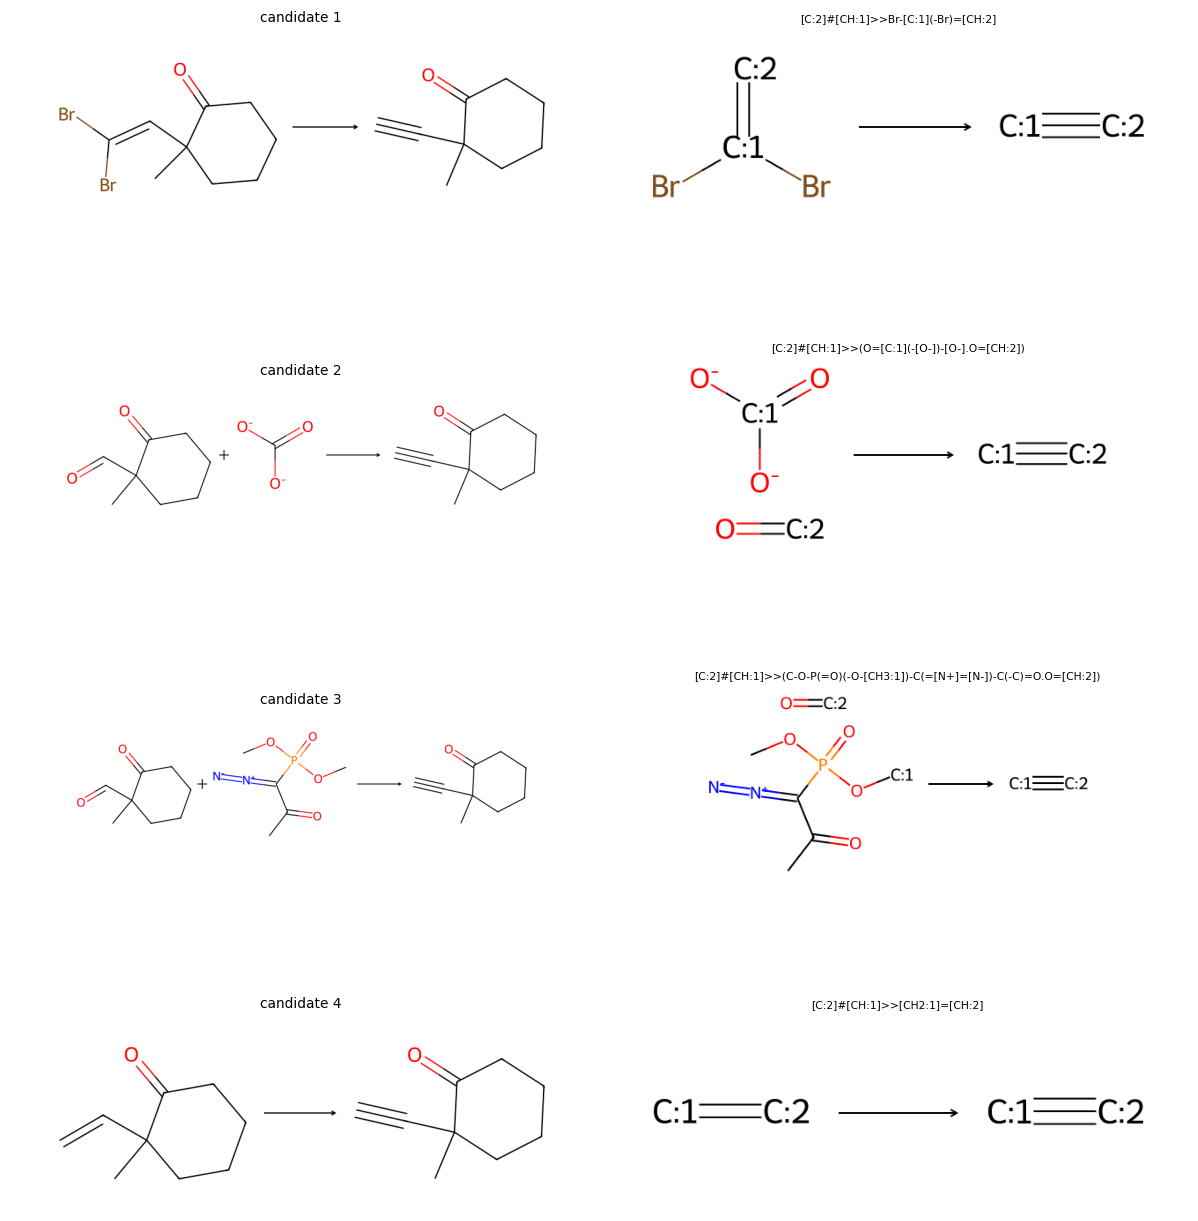

In [18]:
if HAVE_TORCH_RDKIT and unique_reactant_sets:
    product_mol = Chem.MolFromSmiles(target); n_show = min(4, len(unique_reactant_sets))
    fig, axes = plt.subplots(n_show, 2, figsize=(11, 3.2 * n_show), squeeze=False)
    for i in range(n_show):
        img = draw_reaction([Chem.MolFromSmiles(r) for r in unique_reactant_sets[i]], product_mol, 300); tmpl = working_templates[idx[i]]
        axes[i, 0].imshow(img); axes[i, 0].set_title(f"candidate {i + 1}", fontsize=9); axes[i, 1].imshow(draw_reverse_template(tmpl, 220)); axes[i, 1].set_title(tmpl, fontsize=7)
        axes[i, 0].axis("off"); axes[i, 1].axis("off")
    plt.tight_layout(); plt.show()

In [19]:
# the bond map with RDKit's own bond list (more reliable than our string parser) and the authors' model, and a cross-check against Part I's NumPy path
if HAVE_TORCH_RDKIT:
    mol = Chem.MolFromSmiles(target); rows = []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx(); sp = to_map_product(target, [i, j]); si = torch.LongTensor(star_product_string_to_product_star_indices(sp, tokenizer)).to(device)
        with torch.no_grad(): bl = Conditioned_Batch_Beam_Search(x, si.view(-1, 20), modelB, device, smiledict, invdict, max_len=349, beam_size=5)
        top = sorted(((s, float(p)) for s, p in np.array(bl).reshape((-1, 2)).tolist()), key=lambda r: -r[1])[0]; rows.append((f"{i}-{j}", f"{top[1]:.2f}", top[0]))
    print(pd.DataFrame(rows, columns=["bond", "log p", "top-1 template (PyTorch)"]).to_string(index=False))
    if "model_b" in globals():
        agree = sum(model_b(product, [int(r[0].split('-')[0]), int(r[0].split('-')[1])], beam=5)[0][0] == r[2] for r in rows); print(f"NumPy path (Part I) agrees with PyTorch on {agree} of {len(rows)} bonds")

100%|██████████| 347/347 [02:22<00:00,  2.43it/s]


bond log p               top-1 template (PyTorch)
 0-1 -0.57     [C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]
 1-2 -1.49           [C:2]-[C:1]>>Br-[C:1].[CH:2]
 2-3 -0.57        [C:2]-[CH3:1]>>I-[CH3:1].[CH:2]
 2-4 -1.27       [C:2]-[CH2:1]>>Br-[CH2:1].[CH:2]
 4-5 -0.00         [CH2:1]-[CH2:2]>>[CH:1]=[CH:2]
 5-6 -0.01         [CH2:1]-[CH2:2]>>[CH:1]=[CH:2]
 6-7 -0.01         [CH2:1]-[CH2:2]>>[CH:1]=[CH:2]
 7-8 -1.70 [C:1]-[CH2:2]>>C-O-N(-C)-[C:1].[CH3:2]
 8-9 -1.16             [C:1]=[O:2]>>[CH:1]-[OH:2]
 8-2 -0.80          [C:1]-[C:2]>>C-O-[C:1].[CH:2]
NumPy path (Part I) agrees with PyTorch on 9 of 10 bonds
